# The Cost of a Late Box · Olist Deep Dive

The companion Power BI report (*Olist e-commerce*, Jan 2017 – Aug 2018) shows that late orders average **2.3★ against 4.3★** on time,
and that **only 3% of customers ever order twice**. A dashboard can show those facts but can't explain them. This notebook asks four questions:

1. **How much does lateness itself cost in stars,** once price, category, region, basket size and season are held constant?
2. **What do unhappy customers actually write?** Topic modelling on the Portuguese text of 1–2★ reviews.
3. **Does a bad first order explain the missing repeat customers,** or is low retention structural?
4. **What would fixing lateness be worth,** and where should the effort go?

Every definition matches the Power BI model, so the numbers reconcile with the dashboard.

### Key Findings
* **Lateness is a cliff, not a slope.** Arriving early barely changes the score (4.3★ whether 1 or 15 days early), but arriving **1–3 days late** drops it to 3.3★ and **4–7 days late** to 2.1★. With other factors held constant, a 4–7-day delay costs **1.9 stars**.
* **Two-thirds of negative reviews are about fulfilment, not the product.** Of 9,194 written 1–2★ reviews, 66% are about undelivered, partial, late or "shows delivered" orders. Only 30% are about product quality or defects.
* **Many complaints are timing problems.** 27% of negative reviews were written *before* the package arrived (against 5% of all reviews). **Partial deliveries**, the biggest complaint (22%), come from multi-item orders 47% of the time, even though only 10% of orders have more than one item.
* **A bad first order does not explain why customers don't return.** Only 2.0% buy again within 180 days. A late first order lowers that to 1.6%, but with controls the effect is not significant (odds ratio 0.90, p = 0.46). Low retention is structural.
* **Fixing lateness is worth about 3,400 fewer 1–2★ reviews.** That is 28% of all bad reviews. The effort should focus on Feb–Mar 2018 (Carnival), Black Friday and the North-East states (MA, CE, BA).

In [1]:
# ---- where things live -------------------------------------------------------------------------
import os, sys
from pathlib import Path

MAIN_FOLDERS = [Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Radarr"),
                Path(r"C:\Users\Johanna\OneDrive\Documents\Portfolios\Catalyst\ecommerce Brazil")]
DATA_OVERRIDE = r""   # optional: folder that holds the Olist CSV files

def code_folder():
    for p in [Path.cwd(), *Path.cwd().parents]:
        if (p / "olisttools.py").exists():
            return p
    for root in [*MAIN_FOLDERS, Path.cwd()]:
        if root.exists():
            hits = sorted(root.rglob("olisttools.py"), key=lambda f: len(f.parts))
            if hits:
                return hits[0].parent
    return None

CODE = code_folder()
if CODE is None:
    raise FileNotFoundError("olisttools.py not found. Keep it next to this notebook.")
os.chdir(CODE)
sys.path.insert(0, str(CODE))
import olisttools as ot

def data_folder():
    if DATA_OVERRIDE:
        return Path(DATA_OVERRIDE)
    for folder in [CODE / "data", CODE, CODE.parent / "data", CODE.parent, *MAIN_FOLDERS, *[m / "data" for m in MAIN_FOLDERS]]:
        if ot.has_olist(folder):
            return folder
    for root in MAIN_FOLDERS:
        if root.exists():
            for f in sorted(root.rglob("*.csv"), key=lambda f: len(f.parts)):
                if ot.has_olist(f.parent):
                    return f.parent
    return None

DATA = data_folder()
if DATA is None:
    raise FileNotFoundError("Olist CSV files not found. Put them in the data folder, or paste their folder into DATA_OVERRIDE.")

IMAGES = next((p for p in [CODE / "images", CODE.parent / "images"] if p.exists()), CODE / "images")
IMAGES.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight", facecolor="white")

print("Code  :", CODE.name, "| Data:", DATA.name, "| Images:", IMAGES.name)

import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf
from statsmodels.duration.survfunc import SurvfuncRight
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import NMF
from olisttools import NAVY, BLUE, AMBER, GREEN, RED, PURPLE, CYAN, INK, MUTED, LINE, BLUE_L, RED_L

ot.style_charts()
pd.set_option("display.max_colwidth", 80)

Code  : Olist Deep Dive | Data: data | Images: images


## 1 · Same Data, Same Rules as the Dashboard

* **Window:** purchases from Jan 2017 to Aug 2018.
* **Orders:** delivered orders only.
* **Revenue:** item price, excluding freight.
* **Late:** delivered on a later *date* than the estimate.
* **Customers:** counted by `customer_unique_id`.

The check below reproduces the dashboard's headline numbers.

In [2]:
orders, items, reviews = ot.load(DATA)
check = pd.Series({
    "Delivered orders": f"{len(orders):,}",
    "Revenue (R$)": f"{orders.revenue.sum() / 1e6:,.2f} M",
    "Customers": f"{orders.customer_unique_id.nunique():,}",
    "Late delivery %": f"{orders.late.mean():.1%}",
    "Avg review · late": f"{orders.loc[orders.late, 'review_score'].mean():.1f}★",
    "Avg review · on time": f"{orders.loc[~orders.late, 'review_score'].mean():.1f}★",
    "Customers with 2+ orders": f"{(orders.groupby('customer_unique_id').order_id.nunique() > 1).mean():.1%}",
}, name="value").to_frame()
check

,value
Delivered orders,"96,203"
Revenue (R$),13.18 M
Customers,"93,096"
Late delivery %,6.8%
Avg review · late,2.3★
Avg review · on time,4.3★
Customers with 2+ orders,3.0%


## 2 · The Rating Cliff

Splitting orders by how early or late they arrived shows the shape of the effect.

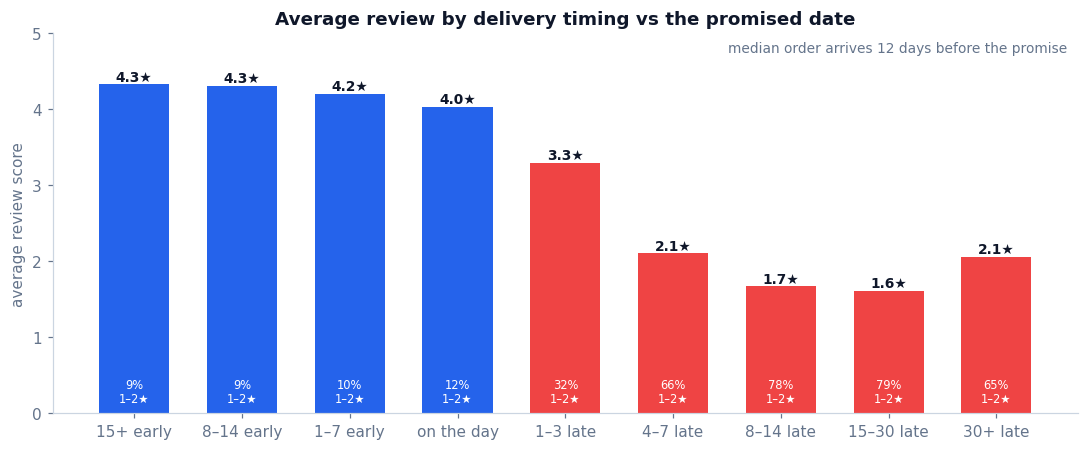

,orders,score,bad
timing,,,
15+ early,"34,693",4.32,9%
8–14 early,"36,353",4.31,9%
1–7 early,"17,335",4.20,10%
on the day,"1,291",4.03,12%
1–3 late,"1,869",3.29,32%
4–7 late,"1,802",2.10,66%
8–14 late,"1,478",1.67,78%
15–30 late,"1,038",1.61,79%
30+ late,344,2.06,65%


In [3]:
bins = [-1000, -15, -8, -1, 0, 3, 7, 14, 30, 1000]
labels = ["15+ early", "8–14 early", "1–7 early", "on the day", "1–3 late", "4–7 late", "8–14 late", "15–30 late", "30+ late"]
orders["timing"] = pd.cut(orders.days_late, bins, labels=labels)
cliff = orders.groupby("timing").agg(orders=("order_id", "size"), score=("review_score", "mean"),
                                     bad=("review_score", lambda x: (x <= 2).mean()))

fig, ax = plt.subplots(figsize=(10, 4.2))
colors = [BLUE if i < 4 else RED for i in range(len(cliff))]
bars = ax.bar(cliff.index.astype(str), cliff.score, color=colors, width=0.65)
for b, (s, bad, n) in zip(bars, cliff[["score", "bad", "orders"]].values):
    ax.text(b.get_x() + b.get_width() / 2, s + 0.05, f"{s:.1f}★", ha="center", fontsize=9, color=INK, fontweight="bold")
    ax.text(b.get_x() + b.get_width() / 2, 0.15, f"{bad:.0%}\n1–2★", ha="center", fontsize=7.5, color="white")
ax.set_ylim(0, 5); ax.set_ylabel("average review score")
ax.set_title("Average review by delivery timing vs the promised date")
ax.text(0.99, 0.95, f"median order arrives {-orders.days_late.median():.0f} days before the promise", transform=ax.transAxes,
        ha="right", fontsize=9, color=MUTED)
plt.tight_layout(); save(fig, "rating cliff"); plt.show()
cliff.style.format({"orders": "{:,}", "score": "{:.2f}", "bad": "{:.0%}"})

**Reading the Chart**
* The median order arrives **12 days before** the promised date. Olist pads its estimates generously, and early delivery adds almost nothing: 4.3★ at 15+ days early and 4.2★ at 1–7 days early.
* The drop starts **the day the promise is missed**. At 1–3 days late, a third of reviews are 1–2★. At 4–7 days late, two-thirds are.
* The 30+ days late group recovers slightly (2.1★). These are often orders that finally arrived after the customer had already complained, so the review captures relief as much as anger.

## 3 · Holding Everything Else Constant

Late orders might differ in other ways: bigger baskets, remote states, cheaper categories or the Black Friday rush.
An OLS regression with robust (HC1) standard errors separates the lateness effect from those factors. It controls for:
order value (log), freight share, number of items, multi-seller orders, same-state shipping, total delivery days, top-15 category, customer state and purchase month.

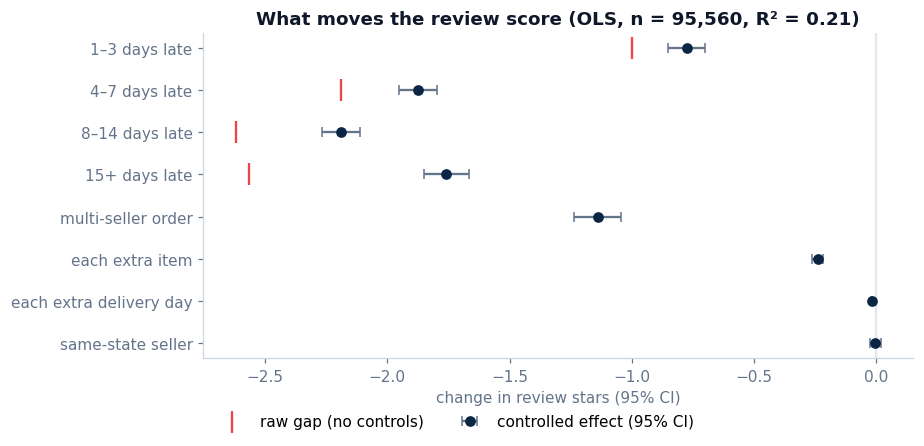

factor,raw gap,controlled effect,ci low,ci high
1–3 days late,-1.00,-0.78,-0.85,-0.70
4–7 days late,-2.19,-1.88,-1.95,-1.80
8–14 days late,-2.62,-2.19,-2.27,-2.11
15+ days late,-2.57,-1.76,-1.85,-1.67
multi-seller order,,-1.14,-1.24,-1.04
each extra item,,-0.24,-0.26,-0.22
each extra delivery day,,-0.02,-0.02,-0.02
same-state seller,,-0.01,-0.03,0.02


In [4]:
m = orders.dropna(subset=["review_score", "revenue", "freight_ratio"]).copy()
m["log_value"] = np.log1p(m.revenue)
top_cats = m.category.value_counts().index[:15]
m["cat"] = np.where(m.category.isin(top_cats), m.category, "other")
m["late_band"] = pd.cut(m.days_late, [-1000, 0, 3, 7, 14, 1000], labels=["on_time", "late_1_3", "late_4_7", "late_8_14", "late_15p"]).astype(str)
m["month_str"] = m.month.astype(str)

formula = ("review_score ~ C(late_band, Treatment('on_time')) + delivery_days + log_value + freight_ratio + items"
           " + multi_seller + same_state + C(cat) + C(customer_state) + C(month_str)")
ols = smf.ols(formula, data=m).fit(cov_type="HC1")
raw = smf.ols("review_score ~ C(late_band, Treatment('on_time'))", data=m).fit(cov_type="HC1")

names = {"late_1_3": "1–3 days late", "late_4_7": "4–7 days late", "late_8_14": "8–14 days late", "late_15p": "15+ days late"}
rows = []
for k, lab in names.items():
    term = f"C(late_band, Treatment('on_time'))[T.{k}]"
    lo, hi = ols.conf_int().loc[term]
    rows.append((lab, raw.params[term], ols.params[term], lo, hi))
for term, lab in [("multi_seller[T.True]", "multi-seller order"), ("items", "each extra item"),
                  ("delivery_days", "each extra delivery day"), ("same_state[T.True]", "same-state seller")]:
    lo, hi = ols.conf_int().loc[term]
    rows.append((lab, np.nan, ols.params[term], lo, hi))
eff = pd.DataFrame(rows, columns=["factor", "raw gap", "controlled effect", "ci low", "ci high"])

fig, ax = plt.subplots(figsize=(8.5, 4.2))
y = np.arange(len(eff))[::-1]
ax.errorbar(eff["controlled effect"], y, xerr=[eff["controlled effect"] - eff["ci low"], eff["ci high"] - eff["controlled effect"]],
            fmt="o", color=NAVY, ecolor=MUTED, capsize=3, label="controlled effect (95% CI)")
ax.scatter(eff["raw gap"], y, marker="|", s=200, color=RED, label="raw gap (no controls)")
ax.axvline(0, color=LINE)
ax.set_yticks(y, eff.factor)
ax.set_xlabel("change in review stars (95% CI)")
ax.set_title(f"What moves the review score (OLS, n = {int(ols.nobs):,}, R² = {ols.rsquared:.2f})")
ax.legend(frameon=False, loc="upper left", bbox_to_anchor=(0.0, -0.13), ncol=2)
plt.tight_layout(); save(fig, "controlled effects"); plt.show()
eff.round(3).style.hide(axis="index").format(precision=2, na_rep="")

**Reading the Model**
* Controls shrink the raw gaps by only 15–30%. **Lateness itself costs 0.8★ at 1–3 days late and about 1.9–2.2★ beyond that.**
* **Multi-seller orders cost 1.1★** even when on time: the customer receives several parcels at different times. Each extra item costs 0.24★.
* **Speed still matters a little when on time.** Each extra day of delivery costs 0.02★, so a 20-day delivery scores about 0.2★ below a 10-day one.
* Same-state shipping has no effect once delivery time is in the model. Distance matters only through delay.

## 4 · What Do Unhappy Customers Write? (Portuguese Text)

The 1–2★ reviews that include a comment are normalised (lower case, accents removed, Portuguese stopwords dropped, but **não** kept)
and modelled with TF-IDF on words and word pairs, then NMF.
Each topic gets an English label, and its **late share** shows how many of its reviews came from orders that actually arrived late.

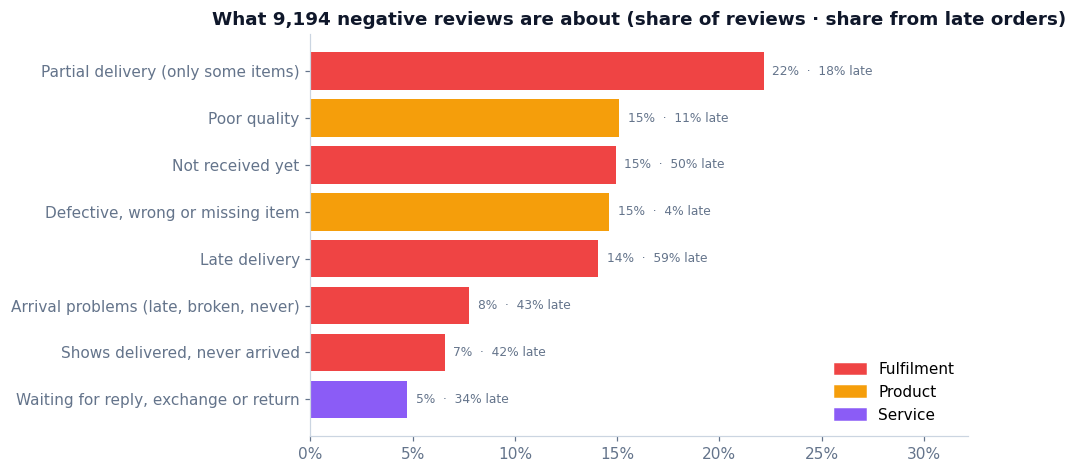

topic,kind,reviews,share,late share,top terms
Partial delivery (only some items),Fulfilment,2039,22%,18%,apenas (only) · dois (two) · recebi apenas (received only) · recebi (received) · duas (two)
Poor quality,Product,1389,15%,11%,qualidade (quality) · gostei (liked) · nao gostei (not liked) · pessima (terrible) · pessima qualidade (terrible quality)
Not received yet,Fulfilment,1372,15%,50%,nao recebi (not received) · recebi (received) · momento (moment (so far)) · momento nao (moment (so far) not) · recebi nao (received not)
"Defective, wrong or missing item",Product,1344,15%,4%,veio (came) · defeito (defect) · nao veio (not came) · veio defeito (came defect) · errado (wrong)
Late delivery,Fulfilment,1295,14%,59%,entrega (delivery) · prazo (deadline) · prazo entrega (deadline delivery) · demora (delay) · entrega nao (delivery not)
"Arrival problems (late, broken, never)",Fulfilment,715,8%,43%,chegou (arrived) · nao chegou (not arrived) · chegou nao (arrived not) · mercadoria (goods) · chegou prazo (arrived deadline)
"Shows delivered, never arrived",Fulfilment,604,7%,42%,entregue (delivered) · nao entregue (not delivered) · entregue nao (delivered not) · momento (moment (so far)) · entregue prazo (delivered deadline)
"Waiting for reply, exchange or return",Service,436,5%,34%,aguardando (waiting) · aguardando entrega (waiting delivery) · retorno (reply) · aguardando retorno (waiting reply) · resposta (answer)


In [5]:
neg = orders[(orders.review_score <= 2) & orders.review_comment_message.notna()].copy()
neg["clean"] = neg.review_comment_message.apply(ot.normalise_pt)
vec = TfidfVectorizer(stop_words=ot.PT_STOP_NORMALISED, min_df=10, max_df=0.5, ngram_range=(1, 2), sublinear_tf=True)
Xt = vec.fit_transform(neg.clean)
terms = np.array(vec.get_feature_names_out())
K = 8
nmf = NMF(K, init="nndsvda", random_state=0, max_iter=800)
W = nmf.fit_transform(Xt)
neg["topic"] = W.argmax(axis=1)

TOPIC_NAMES = {
    0: "Not received yet",
    1: "Shows delivered, never arrived",
    2: "Arrival problems (late, broken, never)",
    3: "Defective, wrong or missing item",
    4: "Late delivery",
    5: "Partial delivery (only some items)",
    6: "Poor quality",
    7: "Waiting for reply, exchange or return",
}
TOPIC_KIND = {0: "Fulfilment", 1: "Fulfilment", 2: "Fulfilment", 3: "Product", 4: "Fulfilment", 5: "Fulfilment", 6: "Product", 7: "Service"}
topics = pd.DataFrame({
    "topic": [TOPIC_NAMES[t] for t in range(K)],
    "kind": [TOPIC_KIND[t] for t in range(K)],
    "reviews": [(neg.topic == t).sum() for t in range(K)],
    "late share": [neg.late[neg.topic == t].mean() for t in range(K)],
    "top terms": [" · ".join(ot.gloss(w) for w in terms[np.argsort(-nmf.components_[t])[:5]]) for t in range(K)],
}).sort_values("reviews", ascending=False)
topics["share"] = topics.reviews / topics.reviews.sum()

fig, ax = plt.subplots(figsize=(9, 4.4))
kind_color = {"Fulfilment": RED, "Product": AMBER, "Service": PURPLE}
t = topics[::-1]
ax.barh(t.topic, t.share, color=[kind_color[k] for k in t.kind])
for yv, (s, l) in enumerate(t[["share", "late share"]].values):
    ax.text(s + 0.004, yv, f"{s:.0%}  ·  {l:.0%} late", va="center", fontsize=8, color=MUTED)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=k) for k, c in kind_color.items()], frameon=False, loc="lower right")
ax.set_title(f"What {len(neg):,} negative reviews are about (share of reviews · share from late orders)")
ax.set_xlim(0, topics.share.max() * 1.45)
plt.tight_layout(); save(fig, "negative review topics"); plt.show()
topics[["topic", "kind", "reviews", "share", "late share", "top terms"]].style.hide(axis="index").format({"share": "{:.0%}", "late share": "{:.0%}"})

In [6]:
EXAMPLES = [  # (a phrase from the review, hand translation)
    ("COMO VOU AVALIAR UM PRODUTO QUE NÃO RECEBI", "How am I supposed to rate a product I haven't received?"),
    ("Produto não foi entregue e não tive resposta", "The product was not delivered and I still have no answer."),
    ("Chegou o produto atrasado, faltando outro", "The product arrived late, with another one missing. The rest still hasn't arrived."),
    ("pedi X veio Y", "It took long to arrive and came different from what I ordered… I ordered X and got Y."),
    ("Já passou o prazo e ainda não recebi", "Delivery takes far too long. The deadline has passed and I still haven't received my order."),
    ("No dois itens comprados veio faltando unidades", "The seller didn't deliver the full order: of the two items I bought, units were missing."),
    ("sinais que ja foram uzados", "I didn't like it: it came with finishing flaws and signs it had already been used."),
    ("Solicitei a devolução e até agora não entraram em contato", "I asked for a return and nobody has contacted me so far."),
]
print("Examples (Portuguese → English):")
for phrase, english in EXAMPLES:
    hit = neg[neg.review_comment_message.str.contains(phrase, regex=False)].head(1)
    for _, r in hit.iterrows():
        print(f"  [{TOPIC_NAMES[r.topic]}]  {r.review_comment_message[:95].strip()}\n      → {english}")

Examples (Portuguese → English):
  [Not received yet]  COMO VOU AVALIAR UM PRODUTO QUE NÃO RECEBI
      → How am I supposed to rate a product I haven't received?
  [Shows delivered, never arrived]  Produto não foi entregue e não tive resposta até hoje
      → The product was not delivered and I still have no answer.
  [Arrival problems (late, broken, never)]  Chegou o produto atrasado, faltando outro. Falta chegar os demais. O cliente está zangado.
      → The product arrived late, with another one missing. The rest still hasn't arrived.
  [Defective, wrong or missing item]  Produto demorou a chegar e veio diferente do que foi pedido... pedi X veio Y, nada haver...
      → It took long to arrive and came different from what I ordered… I ordered X and got Y.
  [Late delivery]  Demora muito entregar. Já passou o prazo e ainda não recebi minha encomenda.
      → Delivery takes far too long. The deadline has passed and I still haven't received my order.
  [Partial delivery (only some items

### Two Clues Behind the Fulfilment Complaints

Many fulfilment complaints come from orders the data marks as *on time*. Two columns explain why:
whether the review was written **before the package arrived**, and whether the order had **more than one item**.

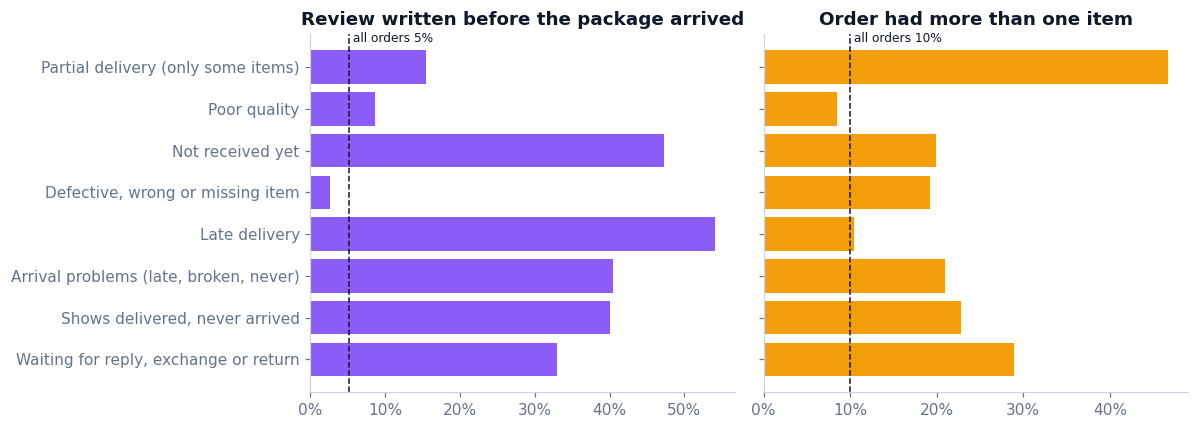

All 1–2★ reviews with text: 27% written before arrival (all reviews: 5%)


In [7]:
clues = (neg.assign(multi_item=neg["items"] > 1)
            .groupby("topic").agg(reviews=("order_id", "size"), before_arrival=("review_before_arrival", "mean"),
                                  multi_item=("multi_item", "mean"), late=("late", "mean")))
clues.index = clues.index.map(TOPIC_NAMES)
clues = clues.loc[topics.topic]
base = pd.Series({"before_arrival": orders.review_before_arrival.mean(), "multi_item": (orders["items"] > 1).mean()})

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, col, colr, title in [(axes[0], "before_arrival", PURPLE, "Review written before the package arrived"),
                             (axes[1], "multi_item", AMBER, "Order had more than one item")]:
    ax.barh(clues.index[::-1], clues[col][::-1], color=colr)
    ax.axvline(base[col], color=INK, ls="--", lw=1)
    ax.text(base[col], len(clues) - 0.4, f" all orders {base[col]:.0%}", fontsize=8, color=INK)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
    ax.set_title(title)
plt.tight_layout(); save(fig, "complaint clues"); plt.show()
print(f"All 1–2★ reviews with text: {neg.review_before_arrival.mean():.0%} written before arrival "
      f"(all reviews: {orders.review_before_arrival.mean():.0%})")

**Reading the Clues**
* **Reviews arrive before the parcel.** 27% of negative reviews were written before the delivery date, against 5% of all reviews. For *late delivery* and *not received yet* the figure is about half. Customers are asked to rate the order while it is still in transit, so the data calls the order "on time" while the customer is already angry.
* **Partial deliveries are a multi-item problem.** 47% of partial-delivery complaints come from orders with more than one item, against 10% of all orders. Items ship separately and arrive at different times.
* Both causes can be fixed in the process: time the review request to the actual delivery, and consolidate or clearly announce split shipments.

**Reading the Topics**
* **Fulfilment topics make up 66% of negative reviews:** partial delivery 22%, not received yet 15%, late delivery 14%, arrival problems 8%, shows delivered but never arrived 7%. **Product** topics (quality, defects, wrong item) make up 30%, and **service** (waiting for a reply or return) 5%.
* Only about 30% of negative reviews come from orders the data flags as late. The clues below explain the rest.

## 5 · Does a Bad First Order Explain the Missing Repeat Customers?

**Repeat** means a second order on a **different day** within 180 days of the first. Same-day second orders are usually a split basket, not loyalty.
Only customers whose first order was placed before 1 Mar 2018 are included, so everyone has a full 180-day follow-up.

Eligible first-time customers: 54,854 · repeat within 180 days: 2.0%
Odds ratio for a late first order (controlled): 0.90  (95% CI 0.67–1.20, p = 0.46)


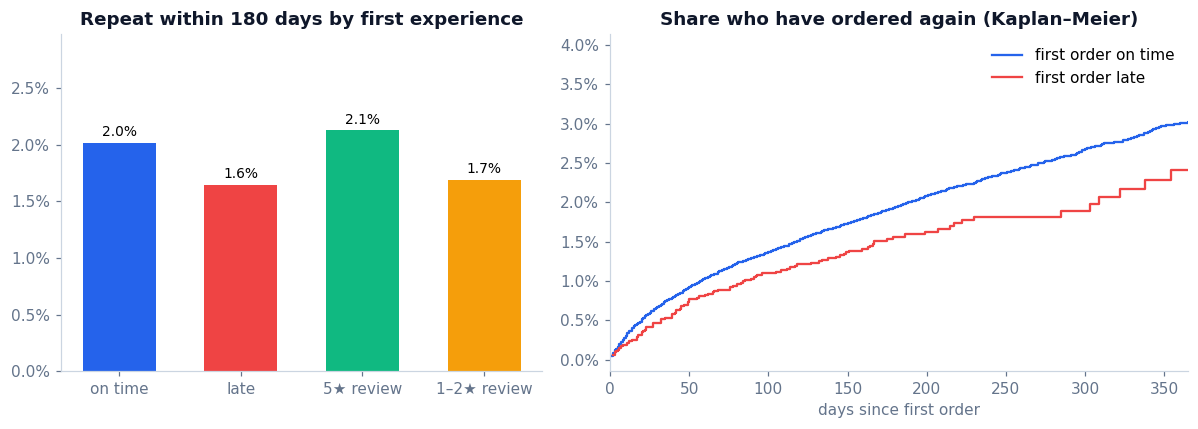

,customers,repeat
cat,,
bed bath table,"5,306",2.8%
sports leisure,"4,463",2.7%
furniture decor,"3,652",2.4%
garden tools,"2,284",2.1%
perfumery,"1,938",2.1%
baby,"1,469",2.0%


In [8]:
first = ot.first_orders(orders)
el = first[first.eligible].dropna(subset=["review_score", "revenue"]).copy()
el["log_value"] = np.log1p(el.revenue)
el["cat"] = np.where(el.category.isin(top_cats), el.category, "other")
el["y"] = el.repeat.astype(int)
el["late_i"] = el.late.astype(int)
logit = smf.logit("y ~ late_i + C(review_score) + log_value + C(cat) + region", data=el).fit(disp=0, maxiter=200)
or_late = np.exp(logit.params["late_i"]); ci = np.exp(logit.conf_int().loc["late_i"])

by_exp = pd.DataFrame({
    "first order": ["on time", "late", "5★ review", "1–2★ review"],
    "customers": [(~el.late).sum(), el.late.sum(), (el.review_score == 5).sum(), (el.review_score <= 2).sum()],
    "repeat within 180 days": [el.repeat[~el.late].mean(), el.repeat[el.late].mean(),
                               el.repeat[el.review_score == 5].mean(), el.repeat[el.review_score <= 2].mean()],
})
print(f"Eligible first-time customers: {len(el):,} · repeat within 180 days: {el.repeat.mean():.1%}")
print(f"Odds ratio for a late first order (controlled): {or_late:.2f}  (95% CI {ci[0]:.2f}–{ci[1]:.2f}, p = {logit.pvalues['late_i']:.2f})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4), gridspec_kw={"width_ratios": [1, 1.2]})
ax = axes[0]
ax.bar(by_exp["first order"], by_exp["repeat within 180 days"], color=[BLUE, RED, GREEN, AMBER], width=0.6)
for i, v in enumerate(by_exp["repeat within 180 days"]):
    ax.text(i, v + 0.0006, f"{v:.1%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_ylim(0, by_exp["repeat within 180 days"].max() * 1.4)
ax.set_title("Repeat within 180 days by first experience")

ax = axes[1]
for flag, colr, lab in [(False, BLUE, "first order on time"), (True, RED, "first order late")]:
    g = first[first.late == flag]
    dur = g.gap.fillna(g.followup).clip(lower=0.5)
    sf = SurvfuncRight(dur.values, g.gap.notna().astype(int).values)
    ax.step(sf.surv_times, 1 - sf.surv_prob, where="post", color=colr, label=lab)
ax.set_xlim(0, 365); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.1%}"))
ax.set_xlabel("days since first order"); ax.set_title("Share who have ordered again (Kaplan–Meier)")
ax.legend(frameon=False)
plt.tight_layout(); save(fig, "repeat purchase"); plt.show()

cat_rep = (el.groupby("cat").agg(customers=("y", "size"), repeat=("y", "mean")).query("customers >= 1000")
             .sort_values("repeat", ascending=False))
cat_rep.head(6).style.format({"customers": "{:,}", "repeat": "{:.1%}"})

**Reading the Retention Results**
* Only **2.0%** of first-time customers buy again within 180 days.
* A late first order is followed by slightly less repeat buying (1.6% vs 2.0%), and so is a 1–2★ first review (1.7% vs 2.1% for 5★). But the controlled odds ratio is 0.90 with a 95% CI of 0.67–1.20. **Bad experiences are not why customers don't come back.** Even delighted customers rarely return.
* Repeat rates are highest in **bed, bath & table (2.8%)** and **sports & leisure (2.7%)**, the categories people restock. A retention programme should start there rather than across the whole marketplace.

## 6 · RFM When Almost Nobody Comes Back

Classic RFM scores Recency, Frequency and Monetary value from 1 to 5. Here, Frequency is 1 for about 97% of customers, so it cannot be split into five groups.
Instead, customers are segmented on **Recency × Monetary** (quintiles), with Frequency kept as a flag.

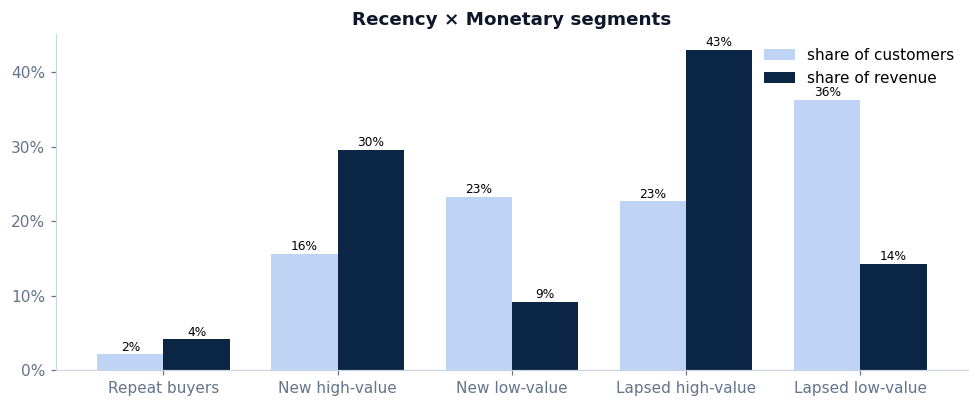

,customers,revenue,avg_value,recency,customer share,revenue share
segment,,,,,,
Repeat buyers,"2,005","R$ 544,289",R$ 271,166 days,2%,4%
New high-value,"14,567","R$ 3,894,425",R$ 267,95 days,16%,30%
New low-value,"21,690","R$ 1,204,724",R$ 56,91 days,23%,9%
Lapsed high-value,"21,100","R$ 5,656,181",R$ 268,310 days,23%,43%
Lapsed low-value,"33,734","R$ 1,880,158",R$ 56,314 days,36%,14%


In [9]:
snapshot = orders.purchase_day.max() + pd.Timedelta(days=1)
cust = orders.groupby("customer_unique_id").agg(last=("purchase_day", "max"), orders=("purchase_day", "nunique"), value=("revenue", "sum"))
cust["recency"] = (snapshot - cust["last"]).dt.days
cust["R"] = pd.qcut(cust.recency, 5, labels=[5, 4, 3, 2, 1]).astype(int)
cust["M"] = pd.qcut(cust.value.rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)

def segment(r):
    if r.orders > 1:
        return "Repeat buyers"
    if r.R >= 4 and r.M >= 4:
        return "New high-value"
    if r.R >= 4:
        return "New low-value"
    if r.M >= 4:
        return "Lapsed high-value"
    return "Lapsed low-value"

cust["segment"] = cust.apply(segment, axis=1)
seg = cust.groupby("segment").agg(customers=("value", "size"), revenue=("value", "sum"), avg_value=("value", "mean"), recency=("recency", "median"))
seg["customer share"] = seg.customers / seg.customers.sum()
seg["revenue share"] = seg.revenue / seg.revenue.sum()
order_ = ["Repeat buyers", "New high-value", "New low-value", "Lapsed high-value", "Lapsed low-value"]
seg = seg.loc[order_]

fig, ax = plt.subplots(figsize=(9, 3.8))
x = np.arange(len(seg)); w = 0.38
ax.bar(x - w / 2, seg["customer share"], w, color=BLUE_L, label="share of customers")
ax.bar(x + w / 2, seg["revenue share"], w, color=NAVY, label="share of revenue")
ax.set_xticks(x, seg.index); ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for i, (a, b) in enumerate(seg[["customer share", "revenue share"]].values):
    ax.text(i - w / 2, a + 0.005, f"{a:.0%}", ha="center", fontsize=8); ax.text(i + w / 2, b + 0.005, f"{b:.0%}", ha="center", fontsize=8)
ax.legend(frameon=False); ax.set_title("Recency × Monetary segments")
plt.tight_layout(); save(fig, "rfm segments"); plt.show()
seg.style.format({"customers": "{:,}", "revenue": "R$ {:,.0f}", "avg_value": "R$ {:,.0f}", "recency": "{:.0f} days",
                  "customer share": "{:.0%}", "revenue share": "{:.0%}"})

**Reading the Segments**
* **Repeat buyers** are only 2% of customers and 4% of revenue.
* **Lapsed high-value** customers (one purchase, top-40% spend, last order about 10 months ago) are 23% of customers but **43% of revenue**. They are the largest win-back pool.
* **New high-value** customers (16% of customers, 30% of revenue) are the ones to protect. A post-delivery check-in and a restock reminder in their category could turn some into repeat buyers before they lapse.

## 7 · What Would Fixing Lateness Be Worth?

Each late order is re-scored as if it had arrived on time, using the controlled effect from section 3 for its lateness band.
Everything else stays as observed.

In [10]:
effect_by_band = {k: ols.params[f"C(late_band, Treatment('on_time'))[T.{k}]"] for k in names}
sim = m.copy()
sim["fixed_score"] = sim.review_score - sim.late_band.map(effect_by_band).fillna(0)
sim["fixed_score"] = sim.fixed_score.clip(1, 5)
late_rows = sim.late_band != "on_time"
bad_now = (sim.review_score <= 2).sum()
bad_late = (sim.loc[late_rows, "review_score"] <= 2).sum()
bad_if_on_time = round(late_rows.sum() * (sim.loc[~late_rows, "review_score"] <= 2).mean())

by_month = (orders.groupby(orders.month.astype(str)).agg(late=("late", "mean"), orders=("order_id", "size")))
worst = by_month.sort_values("late", ascending=False).head(3)
by_state = orders.groupby("customer_state").agg(late=("late", "mean"), orders=("order_id", "size")).query("orders >= 500").sort_values("late", ascending=False)

summary = pd.Series({
    "Average review today": f"{sim.review_score.mean():.2f}★",
    "Average review if every order were on time": f"{sim.fixed_score.mean():.2f}★",
    "1–2★ reviews today": f"{bad_now:,}",
    "…of which on late orders": f"{bad_late:,} ({bad_late / bad_now:.0%})",
    "1–2★ reviews avoided if late orders behaved like on-time ones": f"≈ {bad_late - bad_if_on_time:,}",
    "Worst months for lateness": ", ".join(f"{i} ({v:.0%})" for i, v in worst.late.items()),
    "Worst states (≥ 500 orders)": ", ".join(f"{i} ({v:.0%})" for i, v in by_state.late.head(3).items()),
}, name="").to_frame()
summary

,
Average review today,4.16★
Average review if every order were on time,4.25★
1–2★ reviews today,"12,228"
…of which on late orders,"3,981 (33%)"
1–2★ reviews avoided if late orders behaved like on-time ones,"≈ 3,391"
Worst months for lateness,"2018-03 (19%), 2018-02 (14%), 2017-11 (12%)"
Worst states (≥ 500 orders),"MA (18%), CE (14%), BA (12%)"


**Reading the Simulation**
* If every late order had behaved like an on-time order, the average review would rise from **4.16★ to 4.25★**, and about **3,400 of the 12,228** 1–2★ reviews (28%) would disappear.
* Lateness is concentrated: **Feb–Mar 2018** (Carnival and heavy rains; 19% late in March), **Nov 2017** (Black Friday, 12%) and the North-East states **MA, CE and BA** (12–18%).
* Because early delivery earns nothing extra, moving padding from easy routes to these peak periods and regions would protect ratings at no cost to the rest.

## 8 · What This Adds to the Dashboard

| Dashboard says | Notebook adds |
|---|---|
| Late orders average 2.3★ vs 4.3★ | The effect is a **cliff at the promised date** and survives controls (−0.8★ at 1–3 days late, about −1.9★ beyond). Early delivery buys nothing. |
| Spikes in lateness line up with dips in review score | Two-thirds of negative reviews are **fulfilment** complaints: partial, undelivered or late orders. Many are written **before arrival**, and partial deliveries come mostly from **multi-item** orders. |
| Only 3% of customers order twice | Retention is **structurally low**. A bad first order lowers it only slightly, and not significantly. Restock categories (bed & bath, sports) are the place to start. |
| Remote North states wait longer | The lateness hot spots are **Feb–Mar 2018, Black Friday and MA, CE, BA**. Fixing lateness is worth about 3,400 fewer bad reviews. |

**Recommendations**
1. **Hold the promise, not the speed.** Re-allocate estimate padding to peak months and North-East routes, since early arrivals earn nothing extra.
2. **Consolidate or communicate multi-item orders.** Ship together where possible, and tell the customer which parcel is coming when.
3. **Time the review request to delivery,** not to the estimate, so customers don't rate a product they haven't received.
4. **Start retention in restock categories** with a post-delivery check-in for new high-value customers, and win back the lapsed high-value pool (43% of revenue).

### Limitations
* This is observational data. The controlled estimates remove the confounders I could measure, but not unmeasured ones such as product quality issues that also slow shipping.
* Review scores are only available when the customer leaves one, and unhappy customers are more likely to write a comment, so the text sample leans negative by design.
* Distance is approximated by same-state shipping because geolocation was not part of this extract.